In [1]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris

iris = load_iris()
iris_scaled = StandardScaler().fit_transform(iris.data)


In [2]:
lda = LinearDiscriminantAnalysis(n_components=2)
lda.fit(iris_scaled, iris.target)
iris_lda = lda.transform(iris_scaled)
print(iris_lda.shape)

(150, 2)


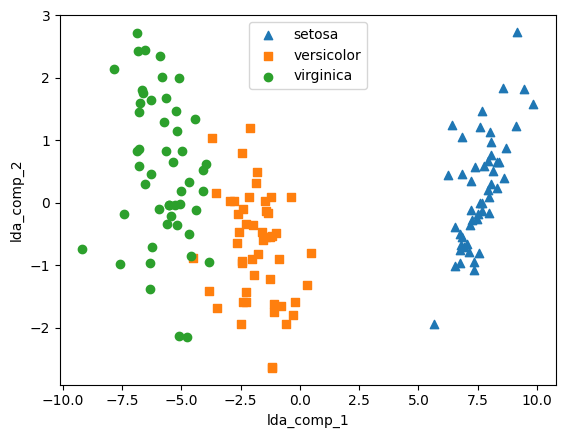

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

lda_columns = ['lda_comp_1', 'lda_comp_2']
irisDF_lda = pd.DataFrame(iris_lda, columns= lda_columns)
irisDF_lda['target'] = iris.target
markers = ['^', 's', 'o']

for i, marker in enumerate(markers):
    x_axis_data = irisDF_lda[irisDF_lda['target'] == i]['lda_comp_1']
    y_axis_data = irisDF_lda[irisDF_lda['target'] == i]['lda_comp_2']
    plt.scatter(x_axis_data, y_axis_data, marker = marker,
                label = iris.target_names[i])

plt.legend()
plt.xlabel('lda_comp_1')
plt.ylabel('lda_comp_2')
plt.show()

Text(0, 0.5, 'TSVD Comp 2')

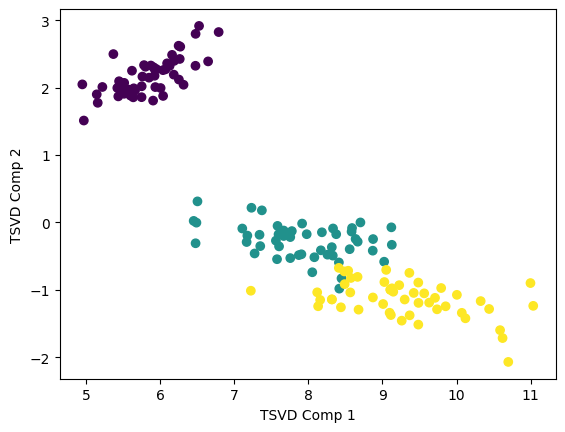

In [4]:
from sklearn.decomposition import TruncatedSVD, PCA

iris = load_iris()
iris_ftrs = iris.data
tsvd = TruncatedSVD(n_components=2)
tsvd.fit(iris_ftrs)
iris_tsvd = tsvd.transform(iris_ftrs)

plt.scatter(x = iris_tsvd[:, 0], y = iris_tsvd[:, 1], c = iris.target)
plt.xlabel('TSVD Comp 1')
plt.ylabel('TSVD Comp 2')

Text(0.5, 1.0, 'PCA Transform')

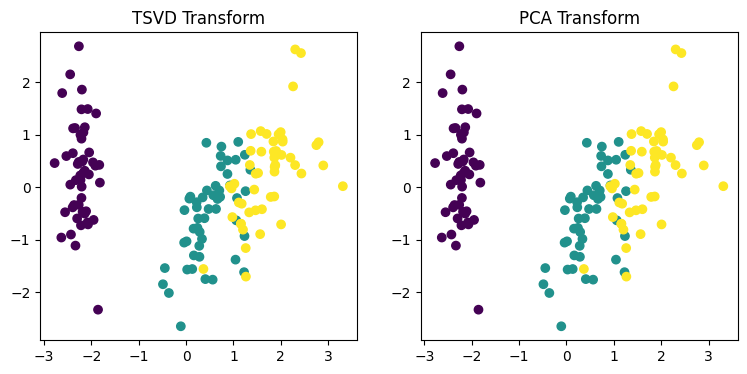

In [9]:
from sklearn.preprocessing import StandardScaler

iris_scaled = StandardScaler().fit_transform(iris_ftrs)


tsvd= TruncatedSVD(n_components=2)
tsvd.fit(iris_scaled)
iris_tsvd = tsvd.transform(iris_scaled)

pca = PCA(n_components= 2)
pca.fit(iris_scaled)
iris_pca = pca.transform(iris_scaled)

fig, (ax1, ax2) = plt.subplots(figsize= (9, 4), ncols= 2)
ax1.scatter(x= iris_tsvd[:, 0], y = iris_tsvd[:,1], c = iris.target)
ax2.scatter(x= iris_pca[:, 0], y = iris_pca[:,1], c = iris.target)

ax1.set_title('TSVD Transform')
ax2.set_title('PCA Transform')

c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\sklearn\decomposition\_nmf.py:289: FutureWarning: The 'init' value, when 'init=None' and n_components is less than n_samples and n_features, will be changed from 'nndsvd' to 'nndsvda' in 1.1 (renaming of 0.26).
  warnings.warn(
c:\Users\KDS38\Documents\ML\.venv\lib\site-packages\sklearn\decomposition\_nmf.py:1637: ConvergenceWarning: Maximum number of iterations 200 reached. Increase it to improve convergence.
  warnings.warn(


Text(0, 0.5, 'NMF Comp 2')

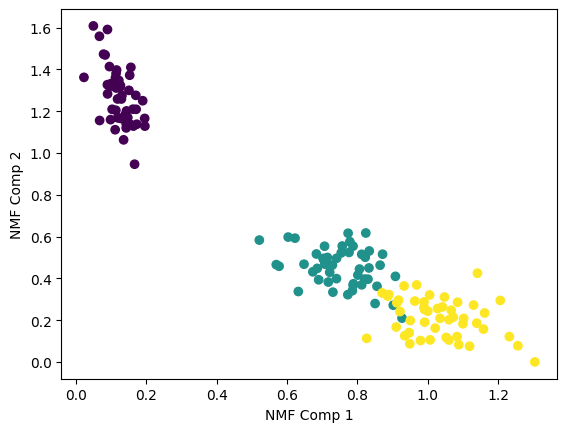

In [8]:
from sklearn.decomposition import NMF

nmf = NMF(n_components= 2)
nmf.fit(iris_ftrs)
iris_nmf = nmf.transform(iris_ftrs)

plt.scatter(x = iris_nmf[:, 0], y = iris_nmf[:, 1], c = iris.target)
plt.xlabel('NMF Comp 1')
plt.ylabel('NMF Comp 2')